## **P1 - Audit of dataset**  
This submission contains a runnable notebook demonstrating the audit of our selected data set for the course IDIG4120 *Digital Information Processing*.

### Task Description
*Describe how your data is actually represented, and test the assumptions everything later depends on. The
baseline you fix here is what P2 measures its compression against.*  
Format, array shape, data type, units, range and byte size.
 - [x ] Sampling rate or spacing. Say so where the concept does not apply, or is unknown.
 - [x ] One time or spatial view and one frequency view, both with labelled axes. See section 2 and 4.
 - [x ] One transform or filtering experiment, with the prediction you made before running it. See section 4.
 - [ x] One resampling or quantisation experiment that finds an artefact or a limitation. See section 3.
 - [ x] A reproducible loader, and the baseline representation P2 will be measured against. See section 2 and 3.
 - [x ] One Visual Informatics concern and one implementation, integrity or security concern that meet in this dataset.
 - [ x] Who did what, and the generative-AI declaration. See section 5.

### 1.) **Pre audit dataset details:** (Repeat of P0)
 
 - **Name**: UrbanSound8k  
 - **Stable source**: Kaggle Link: https://www.kaggle.com/datasets/chrisfilo/urbansound8k  
    - **Retrieval date**: August 25th, 2026  
 - **Licence**: CC BY-NC 4.0 on Kaggle; non-commercial  
 - **Scale**: 8,732 clips at <=4 seconds each with 10 different labels split into 10 folds  
    - **Classes/labels**: air_conditioner, car_horn, children_playing, dog_bark, drilling, engine_idling, gun_shot, jackhammer, siren, and street_music  
 - **File formats**: 8732 .wav files and 1 .csv with metadata and labels  
 - **Representation**: Waveform data, various configurations (source: https://audeering.github.io/audbcards/audb-public/urbansound8k.html)  
    - **Bitdepths**: 4,8,16,24,32  
    - **Channels**: 1,2  
    - **Sampling** rate: 8000, 11024, 11025, 16000, 22050, 24000, 32000, 44100, 48000, 96000, 192000  
 - **Quality risks**: Varying recording quality  
 - **Integrity risks**: Corrupt/malformed files, faulty/incorrect headers (Shouldn't be a problem given other people having used the dataset)  
 - **Security risks**: N/A  


In [6]:
#Imports
from __future__ import annotations

import csv
from collections.abc import Callable
from dataclasses import dataclass
from enum import auto, StrEnum
from io import BytesIO
from logging import getLogger
import numpy as np
from pathlib import Path
from matplotlib import pyplot as plt
from scipy.io import wavfile
import soundfile as sf



In [7]:
#Types and constants

@dataclass
class Metadata:
    file_name: str
    source_bit_depth: int | None
    source_subtype: str
    source_byte_size: int
    decoded_dtype: str
    working_dtype: str
    working_bit_depth: int
    working_byte_size: int
    channel_count: int
    label: CLASSES
    frame_count: int
    sample_rate: int
    amplitude_min: float
    amplitude_max: float


logger = getLogger(__name__)

DATASET_NAME: str = "UrbanSound8k"
DATASET_PATH: Path = Path.cwd() / "archive"
GLOB: str = "fold*/*.wav"

FREQUENCY_BINS: int = 512
MAX_FREQUENCY_HZ: float = 22050.0

LICENSE_STRING = "CC BY-NC 4.0"
SOURCE: str = "https://www.kaggle.com/datasets/chrisfilo/urbansound8k"



#Expected values (based on P0)

#File counts
NUM_FILES: int = 8733
NUM_WAV: int = 8732
NUM_CSV: int = 1


#Classes (specified in metadata.csv)
class CLASSES(StrEnum):
    AC = "air_conditioner"
    CARHORN = "car_horn"
    CHILDREN = "children_playing"
    DOG = "dog_bark"
    DRILL = "drilling"
    ENGINE = "engine_idling"
    GUN = "gun_shot"
    JACK = "jackhammer"
    SIREN = "siren"
    STREETMUSIC = "street_music"
    UNKNOWN = auto()

#Representation
BITDEPTHS: set[int] = {4, 8, 16, 24, 32, 64}
CHANNELS: set[int] = {1, 2}
SAMPLING_RATES: set[int] = {8000, 11024, 11025, 16000, 22050, 24000, 32000, 44100, 48000, 96000, 192000}


AMPLITUDE_MEANING = ("Normalized full-scale sample amplitude. Integer PCM mapped to [-1, 1]. Floating-point WAV samples remain unchanged after decoding.")

SOURCE_BIT_DEPTHS = {
    "PCM_U8": 8,
    "PCM_16": 16,
    "PCM_24": 24,
    "PCM_32": 32,
    "FLOAT": 32,
    "DOUBLE": 64,
    "IMA_ADPCM": 4,
    "MS_ADPCM": 4,
}


### 2.) Dataset loader and audit

Loads the dataset, then audits it: file/format statistics and distributions, and a frequency domain across every file matched by `GLOB`.

{'amplitude_max': 0.9999998807907104,
 'amplitude_min': -1.0,
 'amplitude_units': 'Normalized full-scale sample amplitude. Integer PCM '
                    'mapped to [-1, 1]. Floating-point WAV samples remain '
                    'unchanged after decoding.',
 'average_frame_count': 173863.51946862118,
 'average_playtime': 3.607521829246339,
 'average_sample_rate': 48456.97927164452,
 'failed_filecount': 0,
 'filecount': 8732,
 'matched_filecount': 8732,
 'single_channel_files': 739,
 'source_average_byte_size': 811800.6823179112,
 'source_total_byte_size': 7088643558,
 'total_playtime': 31500.880612979032,
 'valid': 8732,
 'working_average_byte_size': 935728.6312414109,
 'working_total_byte_size': 8170782408}
Source Bit Depth Counts
  16: 5758
  24: 2753
  32: 169
  4: 9
  8: 43
Source Subtype Counts
  FLOAT: 169
  IMA_ADPCM: 1
  MS_ADPCM: 8
  PCM_16: 5758
  PCM_24: 2753
  PCM_U8: 43
Decoded Data Type Counts
  float32: 178
  int16: 5758
  int32: 2753
  uint8: 43
Working Data Type Co

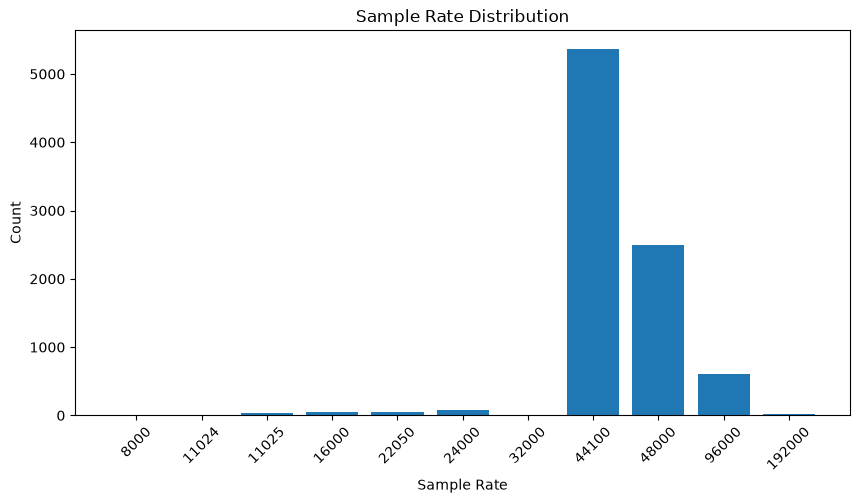

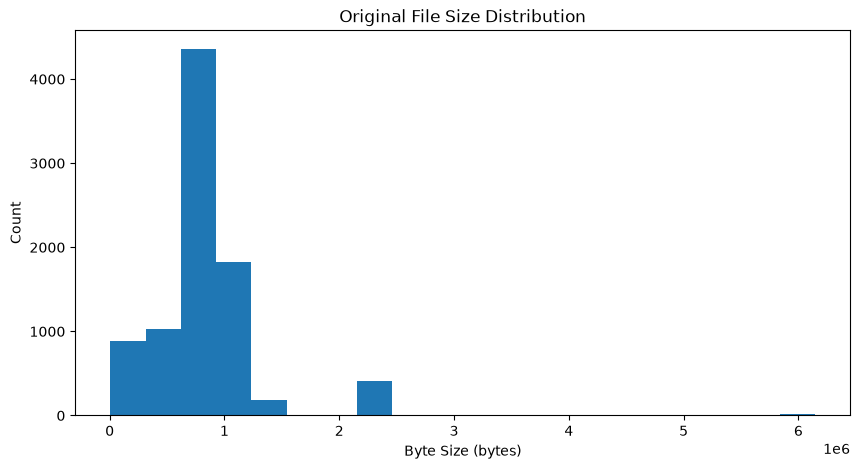

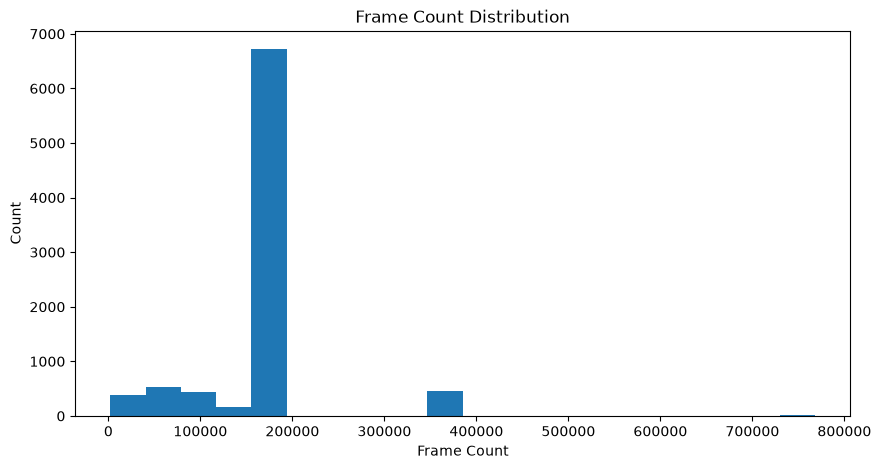

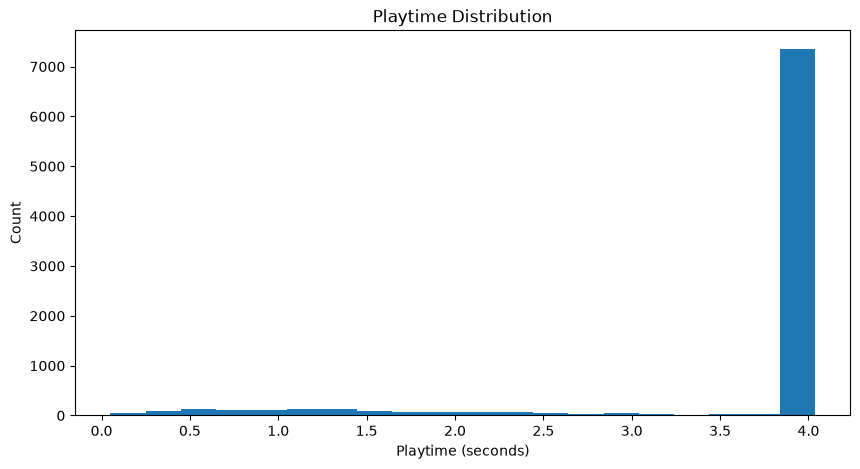

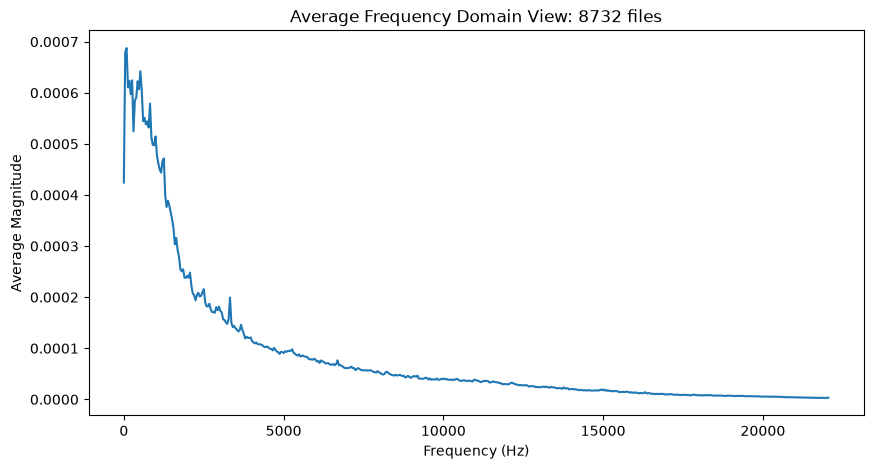

In [3]:
def _log_and_raise(message: str, exception: type[Exception] | Exception) -> None:
    logger.error(f"{message} {exception}")
    if isinstance(exception, type):
        raise exception(message)
    raise exception

def load_dataset(path: Path, transform: Callable[[np.ndarray], np.ndarray] | None = None, visualize: bool = False) -> dict:
    '''
        Loads and audits the dataset located at path.

        Args:
            path: Absolute path to the folder containing the dataset
            transform: Optional per-file transform
            visualize: Whether the audit should also plot its results

        Returns:
            The audit statistics; audio samples are not retained per file to avoid using too much memory
    '''
    logger.info(f"Loading dataset from {path}")
    dataset: list[Metadata] = []
    spectra: list[np.ndarray] = []
    failed_files = 0

    if not path.exists():
        _log_and_raise(f"Dataset path {path} not found", FileNotFoundError)

    if not path.is_dir():
        _log_and_raise(f"Dataset path {path} is not a directory", TypeError)

    #The metadata CSV is optional: without it the audit still runs, every label is just unknown
    csv_path = path / "UrbanSound8K.csv"
    if csv_path.is_file():
        csv_data = load_csv(csv_path)
    else:
        logger.warning(f"Metadata CSV not found at {csv_path}; auditing without class labels")
        csv_data = []

    #Lookup table so we do not search the full CSV for every file
    metadata = {
        row["slice_file_name"]: row
        for row in csv_data
    }

    files = list(path.glob(GLOB))

    for file in files:
        try:
            data, file_metadata = load_wav(file, metadata, transform)
            channel = data[:, 0] if data.ndim > 1 else data

            spectra.append(
                compute_magnitude_spectrum(
                    channel,
                    file_metadata.sample_rate,
                    FREQUENCY_BINS,
                    MAX_FREQUENCY_HZ
                )
            )

            dataset.append(file_metadata)

        except Exception as e:
            failed_files += 1
            logger.warning(f"Skipping {file}, failed to load: {e}")

    statistics = audit_dataset(dataset, spectra)

    statistics["matched_filecount"] = len(files)
    statistics["failed_filecount"] = failed_files

    if visualize:
        visualize_audit(statistics)

    return statistics



def load_wav(path: Path, dataset_: dict[str, dict], transform: Callable[[np.ndarray], np.ndarray] | None = None) -> tuple[np.ndarray, Metadata]:
    '''
        Loads and validates the contents of a single .wav file.

        Args:
            path: Absolute path to the .wav file
            dataset_: CSV metadata
            transform: Optional transform applied to the wav files

        Returns:
            (ndarray, Metadata) a numpy array with wav data and metadata
        
        Raises:
            FileNotFoundError
            RuntimeError
            TypeError
    '''
    if not path.exists():
        _log_and_raise(f"File {path} not found", FileNotFoundError)

    if not path.is_file():
        _log_and_raise(f"File {path} is not a file", TypeError)

    if path.suffix.lower() != ".wav":
        _log_and_raise(f"File {path} is not a .wav file", TypeError)

    try:
        samplerate, decoded_data = _read_wav(path)
        working_data = transform(decoded_data) if transform is not None else decoded_data

        #Get class label from the CSV metadata
        label = CLASSES.UNKNOWN
        csv_metadata = dataset_.get(path.name)

        if csv_metadata is not None:
            class_name = csv_metadata.get("class")

            if class_name is not None:
                label = CLASSES(class_name)

        metadata = get_metadata(
            path,
            samplerate,
            decoded_data,
            working_data,
            label
        )

        return working_data, metadata

    except Exception as e:
        _log_and_raise(f"Failed to load wav file {path}", e)




def _read_wav(path: Path) -> tuple[int, np.ndarray]:
    '''
    Decode WAV audio, uses scipy.io.wavfile as the primary decoder and soundfile as a fallback.

    Args:
        path: Absolute path to the .wav file.

    Returns:
        (samplerate, ndarray) the sample rate and decoded sample data
    '''
    try:
        samplerate, data = wavfile.read(path)
        return samplerate, data

    except (ValueError, NotImplementedError) as scipy_error:
        try:
            data, samplerate = sf.read(path, dtype="float32", always_2d=False)
            return samplerate, data

        except Exception as soundfile_error:
            _log_and_raise(f"Failed to decode WAV file {path}", soundfile_error)


def _wav_byte_size(samplerate: int, data: np.ndarray) -> int:
    '''
        Encodes samples as a WAV in memory to measure the resulting file size.

        Args:
            samplerate: Sample rate of the clip
            data: Sample data to encode

        Returns:
            Size of the encoded WAV in bytes, headers included
    '''
    buffer = BytesIO()
    wavfile.write(buffer, samplerate, data)
    return buffer.getbuffer().nbytes


def pcm_to_float(data: np.ndarray) -> np.ndarray:
    '''
        Convert decoded audio to a common floating-point amplitude scale.

        Args:
            data: Decoded audio samples as a NumPy array.

        Returns:
            Audio samples as a NumPy array of type float64, scaled to [-1.0, 1.0] for integer PCM.
    '''
    x = np.asarray(data)

    if np.issubdtype(x.dtype, np.floating):
        return x.astype(np.float64)

    if x.dtype == np.uint8:
        #Shift unsigned 8-bit PCM to signed range
        return (x.astype(np.float64) - 128.0) / 128.0

    if np.issubdtype(x.dtype, np.signedinteger):
        info = np.iinfo(x.dtype)
        #Change integer PCM to float in the range [-1, 1]
        return x.astype(np.float64) / abs(info.min)

    raise TypeError(f"Unsupported audio dtype: {x.dtype}")



def get_metadata(path: Path, samplerate: int, decoded_data: np.ndarray, working_data: np.ndarray, label: CLASSES = CLASSES.UNKNOWN) -> Metadata:
    '''
        Computes and returns metadata from already-read wav file contents.

        Args:
            path: Absolute path to the .wav file
            samplerate: Sample rate of the wav file
            decoded_data: Original data returned by the decoder
            working_data: Data after an optional transform
            label: Class label of the file

        Returns:
            Metadata class containing source and working metadata
    '''
    info = sf.info(path)
    normalized = pcm_to_float(working_data)

    return Metadata(
        file_name = path.name,
        source_bit_depth = get_source_bit_depth(info.subtype),
        source_subtype = info.subtype,
        source_byte_size = path.stat().st_size,
        decoded_dtype = str(decoded_data.dtype),
        working_dtype = str(working_data.dtype),
        working_bit_depth = working_data.dtype.itemsize * 8,
        working_byte_size = _wav_byte_size(samplerate, working_data),
        channel_count = working_data.shape[1] if working_data.ndim > 1 else 1,
        label = label,
        frame_count = working_data.shape[0],
        sample_rate = samplerate,
        amplitude_min = float(np.min(normalized)),
        amplitude_max = float(np.max(normalized))
    )


def get_source_bit_depth(subtype: str) -> int | None:
    '''
    Get bit depth of given WAV subtype
    
    Args:
        subtype: WAV subtype string.

    Returns:
        Bit depth of the given WAV subtype, or None if unknown.
    '''
    return SOURCE_BIT_DEPTHS.get(subtype)


def load_csv(path: Path) -> list[dict]:
    '''
        Loads and validates the contents of a CSV file.

        Args:
            path: Absolute path to the CSV file.

        Returns:
            List of dictionaries containing CSV data.

        Raises:
            FileNotFoundError
            RuntimeError
            TypeError
    '''
    if not path.exists():
        _log_and_raise(f"File {path} not found", FileNotFoundError)

    if not path.is_file():
        _log_and_raise(f"File {path} is not a file", TypeError)

    if path.suffix.lower() != ".csv":
        _log_and_raise(f"File {path} is not a .csv file", TypeError)

    try:
        with open(path, newline='') as csvfile:
            reader = csv.DictReader(csvfile)
            return [row for row in reader]
    except Exception as e:
        _log_and_raise(f"Failed to read CSV file {path}", e)


def validate_wav(metadata: Metadata) -> bool:
    '''
        Validates the metadata of a wav file.

        Args:
            metadata: Metadata object containing wav file information.

        Returns:
            True if the wav file metadata is valid, False otherwise.
    '''
    issue = False
    logger.info(f"Validating wav metadata for file: {metadata.file_name}")

    #Bit depth
    if metadata.source_bit_depth is None:
        logger.warning(f"\tUnknown source bit depth: {metadata.source_subtype}")
        issue = True
    elif metadata.source_bit_depth not in BITDEPTHS:
        logger.warning(f"\tUnexpected bit depth: {metadata.source_bit_depth}")
        issue = True
    #Channel count
    if metadata.channel_count not in CHANNELS:
        logger.warning(f"\tUnexpected channel count: {metadata.channel_count}")
        issue = True
    #Frame count
    if metadata.frame_count <= 0:
        logger.warning(f"\tInvalid frame count: {metadata.frame_count}")
        issue = True
    #Sample rate
    if metadata.sample_rate not in SAMPLING_RATES:
        logger.warning(f"\tInvalid sample rate: {metadata.sample_rate}")
        issue = True

    return not issue


def audit_dataset(dataset: list[Metadata], spectra: list[np.ndarray]) -> dict:
    '''
        Computes audit statistics for the given metadata.

        Args:
            dataset: Metadata records to audit
            spectra: Magnitude spectra, carried in the statistics for the frequency view
            visualize: Whether to also plot the statistics

        Returns:
            The audit statistics
    '''
    statistics = {
        "filecount": 0,
        "valid": 0,
        "source_bitdepth_counts": dict(),
        "source_subtype_counts": dict(),
        "source_byte_sizes": [],
        "source_total_byte_size": 0,
        "source_average_byte_size": 0,
        "decoded_dtype_counts": dict(),
        "working_dtype_counts": dict(),
        "working_bitdepth_counts": dict(),
        "working_byte_sizes": [],
        "working_total_byte_size": 0,
        "working_average_byte_size": 0,
        "sample_rate_counts": dict(),
        "average_sample_rate": 0,
        "single_channel_files": 0,
        "frame_counts": [],
        "average_frame_count": 0,
        "playtimes": [],
        "average_playtime": 0.0,
        "total_playtime": 0.0,
        "amplitude_min": None,
        "amplitude_max": None,
        "amplitude_units": AMPLITUDE_MEANING,
        "spectra": spectra
    }
    for metadata in dataset:
        statistics["filecount"] += 1

        if validate_wav(metadata):
            statistics["valid"] += 1

        if statistics["source_bitdepth_counts"].get(metadata.source_bit_depth) is None:
            statistics["source_bitdepth_counts"][metadata.source_bit_depth] = 0
        statistics["source_bitdepth_counts"][metadata.source_bit_depth] += 1

        if statistics["source_subtype_counts"].get(metadata.source_subtype) is None:
            statistics["source_subtype_counts"][metadata.source_subtype] = 0
        statistics["source_subtype_counts"][metadata.source_subtype] += 1

        if statistics["decoded_dtype_counts"].get(metadata.decoded_dtype) is None:
            statistics["decoded_dtype_counts"][metadata.decoded_dtype] = 0
        statistics["decoded_dtype_counts"][metadata.decoded_dtype] += 1

        if statistics["working_dtype_counts"].get(metadata.working_dtype) is None:
            statistics["working_dtype_counts"][metadata.working_dtype] = 0
        statistics["working_dtype_counts"][metadata.working_dtype] += 1

        if statistics["working_bitdepth_counts"].get(metadata.working_bit_depth) is None:
            statistics["working_bitdepth_counts"][metadata.working_bit_depth] = 0
        statistics["working_bitdepth_counts"][metadata.working_bit_depth] += 1

        if statistics["sample_rate_counts"].get(metadata.sample_rate) is None:
            statistics["sample_rate_counts"][metadata.sample_rate] = 0
        statistics["sample_rate_counts"][metadata.sample_rate] += 1

        if metadata.channel_count == 1:
            statistics["single_channel_files"] += 1

        statistics["source_byte_sizes"].append(metadata.source_byte_size)
        statistics["source_total_byte_size"] += metadata.source_byte_size

        statistics["working_byte_sizes"].append(metadata.working_byte_size)
        statistics["working_total_byte_size"] += metadata.working_byte_size

        statistics["frame_counts"].append(metadata.frame_count)

        playtime = metadata.frame_count / metadata.sample_rate
        statistics["playtimes"].append(playtime)
        statistics["total_playtime"] += playtime

        if statistics["amplitude_min"] is None or metadata.amplitude_min < statistics["amplitude_min"]:
            statistics["amplitude_min"] = metadata.amplitude_min

        if statistics["amplitude_max"] is None or metadata.amplitude_max > statistics["amplitude_max"]:
            statistics["amplitude_max"] = metadata.amplitude_max

    statistics["average_sample_rate"] = sum([k * v for k, v in statistics["sample_rate_counts"].items()]) / statistics["filecount"] if statistics["filecount"] > 0 else 0

    statistics["source_average_byte_size"] = statistics["source_total_byte_size"] / statistics["filecount"] if statistics["filecount"] > 0 else 0
    statistics["working_average_byte_size"] = statistics["working_total_byte_size"] / statistics["filecount"] if statistics["filecount"] > 0 else 0

    statistics["average_frame_count"] = sum(statistics["frame_counts"]) / statistics["filecount"] if statistics["filecount"] > 0 else 0
    statistics["average_playtime"] = statistics["total_playtime"] / statistics["filecount"] if statistics["filecount"] > 0 else 0

    return statistics

def _plot_counts(counts: dict, title: str, xlabel: str, rotation: int = 0) -> None:
    labels = sorted(counts.keys())
    plt.figure(figsize=(10, 5))
    plt.bar(range(len(labels)), [counts[k] for k in labels])
    plt.xticks(range(len(labels)), labels, rotation=rotation)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.show()


def _print_table(counts: dict, title: str) -> None:
    print(title)
    for key in sorted(counts.keys(), key=str):
        print(f"  {key}: {counts[key]}")


def _plot_histogram(values: list, title: str, xlabel: str) -> None:
    plt.figure(figsize=(10, 5))
    plt.hist(sorted(values), bins=20)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.show()


def visualize_audit(statistics: dict) -> None:
    import pprint

    excluded = (
        "source_byte_sizes",
        "working_byte_sizes",
        "frame_counts",
        "playtimes",
        "source_bitdepth_counts",
        "source_subtype_counts",
        "decoded_dtype_counts",
        "working_dtype_counts",
        "working_bitdepth_counts",
        "sample_rate_counts",
        "spectra"
    )

    pprint.pprint({
        k: v
        for k, v in statistics.items()
        if k not in excluded
    })

    _print_table(
        statistics["source_bitdepth_counts"],
        "Source Bit Depth Counts"
    )

    _print_table(
        statistics["source_subtype_counts"],
        "Source Subtype Counts"
    )

    _print_table(
        statistics["decoded_dtype_counts"],
        "Decoded Data Type Counts"
    )

    _print_table(
        statistics["working_dtype_counts"],
        "Working Data Type Counts"
    )

    _print_table(
        statistics["working_bitdepth_counts"],
        "Working Bit Depth Counts"
    )

    _plot_counts(
        statistics["sample_rate_counts"],
        "Sample Rate Distribution",
        "Sample Rate",
        rotation=45
    )

    _plot_histogram(
        statistics["source_byte_sizes"],
        "Original File Size Distribution",
        "Byte Size (bytes)"
    )

    _plot_histogram(
        statistics["frame_counts"],
        "Frame Count Distribution",
        "Frame Count"
    )

    _plot_histogram(
        statistics["playtimes"],
        "Playtime Distribution",
        "Playtime (seconds)"
    )

    if statistics["spectra"]:
        plot_frequency_view_all_files(statistics["spectra"])


def compute_magnitude_spectrum(data: np.ndarray, samplerate: int, n_bins: int, max_freq: float) -> np.ndarray:
    '''
        Computes a normalized magnitude spectrum for the given audio data.

        Args:
            data: Decoded single-channel sample data
            samplerate: Sample rate of the clip
            n_bins: Number of bins
            max_freq: Max frequency in Hz

        Returns:
            ndarray of length n_bins with magnitude values
    '''
    data = pcm_to_float(data)

    if len(data) < 2:
        return np.full(n_bins, np.nan)

    #Center the signal around zero
    data = data - np.mean(data)

    #Hanning to fade signal edges
    window = np.hanning(len(data))

    #Find strength of frequencies
    spectrum = np.abs(np.fft.rfft(data * window)) / np.sum(window)

    #Find which frequencies the FFT values represent
    freqs = np.fft.rfftfreq(data.shape[0], d=1 / samplerate)

    #Use the same frequency scale for every file
    common_freqs = np.linspace(0, max_freq, n_bins)

    result = np.full(n_bins, np.nan)
    valid = common_freqs <= samplerate / 2
    result[valid] = np.interp(common_freqs[valid], freqs, spectrum)

    return result


def plot_frequency_view_all_files(spectra: list[np.ndarray], n_bins: int = FREQUENCY_BINS, max_freq: float = MAX_FREQUENCY_HZ) -> None:
    '''
        Displays the average frequency spectrum for all files.

        Args:
            spectra: Magnitude spectra
            n_bins: Number of frequency bins
            max_freq: Maximum frequency in Hz
    '''
    common_freqs = np.linspace(0, max_freq, n_bins)
    spectra = np.asarray(spectra)

    mean_spectrum = np.nanmean(spectra, axis=0)

    plt.figure(figsize=(10, 5))
    plt.plot(common_freqs, mean_spectrum)

    plt.title(f"Average Frequency Domain View: {len(spectra)} files")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Average Magnitude")
    plt.show()


baseline_statistics = load_dataset(DATASET_PATH)
visualize_audit(baseline_statistics)


### 3.) Quantisation experiment

**Expectation:** The loader is run again, this time with a transform that forces every file onto the int16 range regardless of its native bit depth. The resulting audit can be compared against the audit in section 2). Bit depths already at or below 16-bit should show no real change (false precision), while 24/32-bit or float files should show real amplitude range and byte size changes.

This experiment also fixes the baseline representation P2 will be measured against: P2 compresses the int16-quantized samples, so the 16-bit PCM payload of those samples (604.31 MiB for fold1, WAV headers aside), not the on-disk byte size of the source files, is what P2 measures its compression ratio against.

{'amplitude_max': 0.999969482421875,
 'amplitude_min': -1.0,
 'amplitude_units': 'Normalized full-scale sample amplitude. Integer PCM '
                    'mapped to [-1, 1]. Floating-point WAV samples remain '
                    'unchanged after decoding.',
 'average_frame_count': 173863.51946862118,
 'average_playtime': 3.607521829246339,
 'average_sample_rate': 48456.97927164452,
 'failed_filecount': 0,
 'filecount': 8732,
 'matched_filecount': 8732,
 'single_channel_files': 739,
 'source_average_byte_size': 811800.6823179112,
 'source_total_byte_size': 7088643558,
 'total_playtime': 31500.880612979032,
 'valid': 8732,
 'working_average_byte_size': 670305.7333944114,
 'working_total_byte_size': 5853109664}
Source Bit Depth Counts
  16: 5758
  24: 2753
  32: 169
  4: 9
  8: 43
Source Subtype Counts
  FLOAT: 169
  IMA_ADPCM: 1
  MS_ADPCM: 8
  PCM_16: 5758
  PCM_24: 2753
  PCM_U8: 43
Decoded Data Type Counts
  float32: 178
  int16: 5758
  int32: 2753
  uint8: 43
Working Data Type Cou

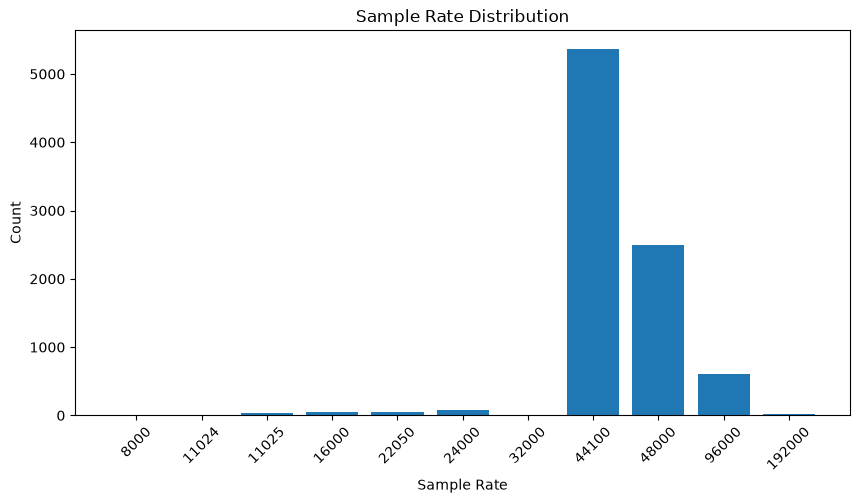

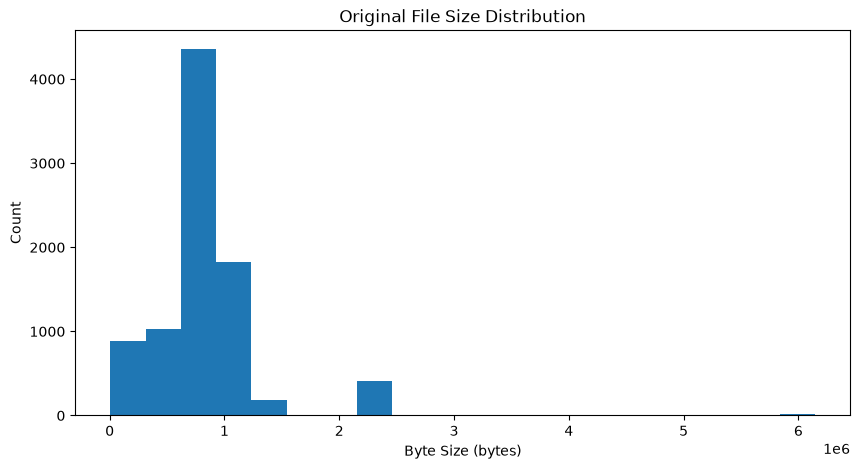

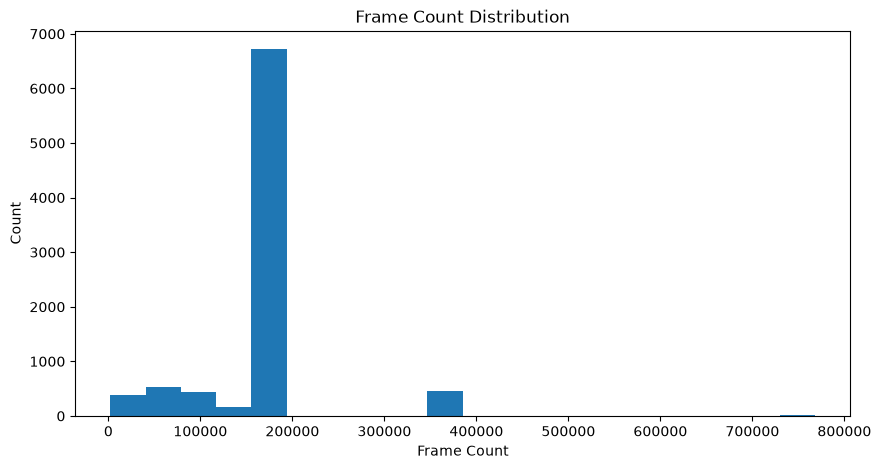

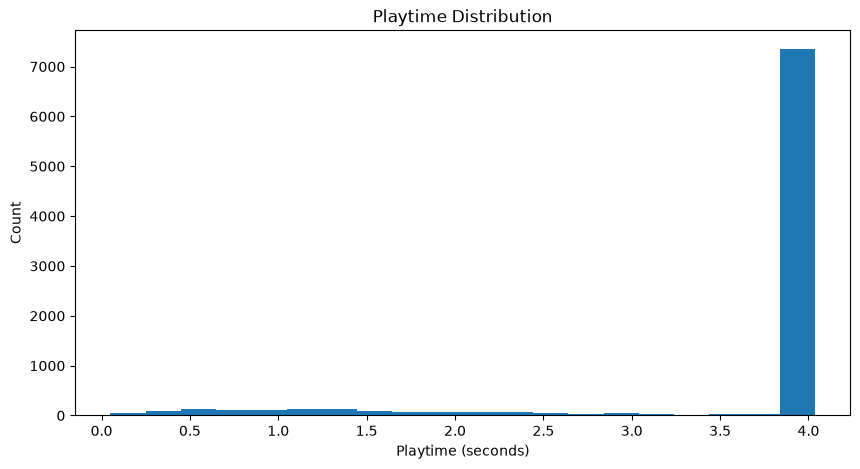

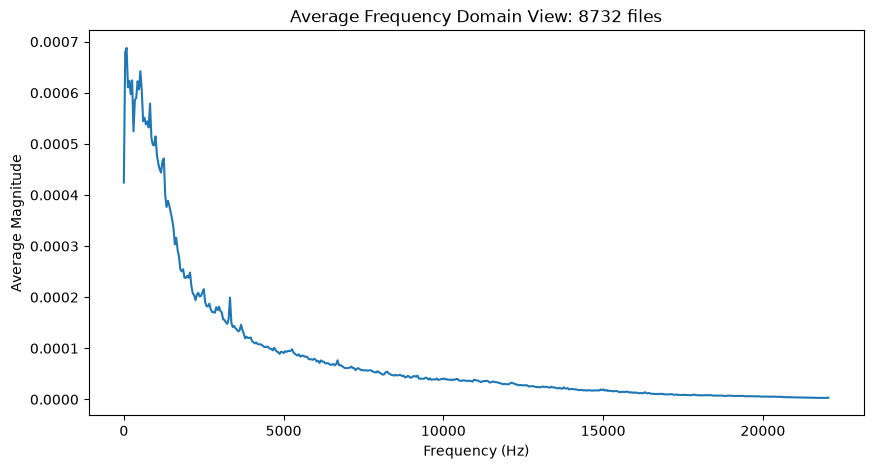


Quantization Experiment
Original size: 6760.26 MiB
Int16 size: 5581.96 MiB
Size change: -17.43%
Mean RMSE: 0.00000276

RMSE by source format
Subtype            Files       Mean RMSE        Max RMSE
FLOAT                169      0.00000867      0.00000883
IMA_ADPCM              1      0.00000000      0.00000000
MS_ADPCM               8      0.00000000      0.00000000
PCM_16              5758      0.00000000      0.00000000
PCM_24              2753      0.00000823      0.00001325
PCM_U8                43      0.00000000      0.00000000


In [4]:
def quantize_to_int16(data: np.ndarray) -> np.ndarray:
    '''
        Quantizes decoded samples to signed 16-bit PCM.

        Args:
            data: Decoded sample data, any numeric dtype

        Returns:
            np.ndarray of int16 samples
    '''
    if data.dtype == np.int16:
        return data.copy()
    
    floating = pcm_to_float(data)

    #Round before conversion
    quantized = np.rint(floating * 32768.0)
    quantized = np.clip(quantized, -32768, 32767)

    return quantized.astype(np.int16)

def get_quantization_error(data: np.ndarray) -> tuple[float, float]:
    '''
        Calculates the error introduced by int16 quantization.

        Args:
            data: Original decoded sample data

        Returns:
            (RMSE, SNR in dB)
    '''
    original = pcm_to_float(data)
    quantized = quantize_to_int16(data)

    #Convert back to original precision
    reconstructed = quantized.astype(np.float64) / 32768.0

    error = original - reconstructed

    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)

    signal_power = np.mean(original ** 2)

    if mse == 0:
        snr = np.inf
    elif signal_power == 0:
        snr = 0
    else:
        snr = 10 * np.log10(signal_power / mse)

    return float(rmse), float(snr)


def quantization_rmse(data: np.ndarray) -> float:
    '''
        Measures the error introduced by int16 quantization.

        Args:
            data: Original decoded sample data

        Returns:
            RMSE between the original and quantized signal
    '''
    original = pcm_to_float(data)
    quantized = quantize_to_int16(data)

    #Convert back to the same scale as the original
    reconstructed = quantized.astype(np.float64) / 32768.0

    #Measure the difference between the signals
    error = original - reconstructed
    rmse = np.sqrt(np.mean(error ** 2))

    return float(rmse)


def run_quantization_rmse(path: Path) -> dict:
    '''
        Measures quantization error for all WAV files.

        Args:
            path: Path to the dataset

        Returns:
            Quantization results grouped by source subtype
    '''
    results = dict()

    for file in path.glob(GLOB):
        try:
            _, data = _read_wav(file)
            subtype = sf.info(file).subtype
            rmse = quantization_rmse(data)

            if subtype not in results:
                results[subtype] = {
                    "count": 0,
                    "rmse": []
                }

            results[subtype]["count"] += 1
            results[subtype]["rmse"].append(rmse)

        except Exception as e:
            logger.warning(f"Could not measure quantization error for {file}: {e}")

    #Summarize the results
    for subtype in results:
        values = np.asarray(results[subtype]["rmse"])

        results[subtype]["mean_rmse"] = float(np.mean(values))
        results[subtype]["max_rmse"] = float(np.max(values))

        del results[subtype]["rmse"]

    return results


def print_quantization_results(results: dict, statistics: dict) -> None:
    '''
        Displays the main results from the quantization experiment.

        Args:
            results: RMSE results grouped by source subtype
            statistics: Audit statistics after int16 conversion
    '''
    original_bytes = statistics["source_total_byte_size"]
    quantized_bytes = statistics["working_total_byte_size"]

    size_change = 100 * (quantized_bytes - original_bytes) / original_bytes

    all_count = sum(result["count"] for result in results.values())

    mean_rmse = sum(
        result["mean_rmse"] * result["count"]
        for result in results.values()
    ) / all_count

    print("\nQuantization Experiment")
    print(f"Original size: {original_bytes / 2**20:.2f} MiB")
    print(f"Int16 size: {quantized_bytes / 2**20:.2f} MiB")
    print(f"Size change: {size_change:+.2f}%")
    print(f"Mean RMSE: {mean_rmse:.8f}")

    print("\nRMSE by source format")
    print(f"{'Subtype':<15} {'Files':>8} {'Mean RMSE':>15} {'Max RMSE':>15}")

    for subtype in sorted(results):
        result = results[subtype]

        print(
            f"{subtype:<15} "
            f"{result['count']:>8} "
            f"{result['mean_rmse']:>15.8f} "
            f"{result['max_rmse']:>15.8f}"
        )


#Run dataset audit with int16 conversion
quantized_statistics = load_dataset(
    DATASET_PATH,
    transform=quantize_to_int16
)

visualize_audit(quantized_statistics)

#Measure the error introduced by quantization
quantization_results = run_quantization_rmse(DATASET_PATH)

print_quantization_results(
    quantization_results,
    quantized_statistics
)



### 4.) High frequency filtering

**Expectation:** Each file in fold1 has its weak Fourier components removed, keeping only coefficients at or above a fraction of the strongest component in each channel. As the fraction rises, the sparse representation should shrink, and the reconstruction error should grow slowly at first.


In [5]:
# Thresholds are fractions of the strongest Fourier magnitude in each channel.
# 0.001 means coefficients below 0.1% of that channel's strongest component are removed.
FOURIER_THRESHOLDS = [0.0, 0.001, 0.005, 0.01, 0.02, 0.05]


def prune_fourier_components(signal: np.ndarray, threshold_ratio: float):
    '''Remove weak rFFT coefficients and return a sparse representation.'''
    spectrum = np.fft.rfft(signal, axis=0)
    magnitude = np.abs(spectrum)

    if spectrum.ndim == 1:
        strongest = magnitude.max()
    else:
        # Apply the same relative rule independently to each channel.
        strongest = magnitude.max(axis=0, keepdims=True)

    cutoff = threshold_ratio * strongest
    keep_mask = magnitude >= cutoff

    flat_mask = keep_mask.reshape(-1)
    indices = np.flatnonzero(flat_mask).astype(np.uint32)
    values = spectrum.reshape(-1)[flat_mask].astype(np.complex64)

    return indices, values, spectrum.shape, keep_mask


def sparse_fourier_file_size(
    indices: np.ndarray,
    values: np.ndarray,
    spectrum_shape: tuple[int, ...],
    n_samples: int,
    sample_rate: int,
) -> int:
    '''Serialize the sparse coefficients in memory and return the resulting byte size.'''
    buffer = BytesIO()
    np.savez_compressed(
        buffer,
        indices=indices,
        values=values,
        spectrum_shape=np.asarray(spectrum_shape, dtype=np.int32),
        n_samples=np.asarray([n_samples], dtype=np.int32),
        sample_rate=np.asarray([sample_rate], dtype=np.int32),
    )
    return buffer.tell()


def reconstruct_from_sparse_fourier(
    indices: np.ndarray,
    values: np.ndarray,
    spectrum_shape: tuple[int, ...],
    n_samples: int,
) -> np.ndarray:
    '''Reconstruct a waveform from the retained sparse Fourier coefficients.'''
    sparse_spectrum = np.zeros(np.prod(spectrum_shape), dtype=np.complex64)
    sparse_spectrum[indices] = values
    sparse_spectrum = sparse_spectrum.reshape(spectrum_shape)

    return np.fft.irfft(
        sparse_spectrum,
        n=n_samples,
        axis=0
    ).astype(np.float32)


def rmse(reference: np.ndarray, reconstructed: np.ndarray) -> float:
    return float(
        np.sqrt(
            np.mean(
                (reference.astype(np.float64) - reconstructed) ** 2
            )
        )
    )

In [8]:
# Thresholds are fractions of the strongest Fourier magnitude in each channel.
# 0.001 means coefficients below 0.1% of that channel's strongest component are removed.
FOURIER_THRESHOLDS = [0.0, 0.001, 0.005, 0.01, 0.02, 0.05]


def prune_fourier_components(signal: np.ndarray, threshold_ratio: float):
    '''Remove weak rFFT coefficients and return a sparse representation.'''
    spectrum = np.fft.rfft(signal, axis=0)
    magnitude = np.abs(spectrum)

    if spectrum.ndim == 1:
        strongest = magnitude.max()
    else:
        # Apply the same relative rule independently to each channel.
        strongest = magnitude.max(axis=0, keepdims=True)

    cutoff = threshold_ratio * strongest
    keep_mask = magnitude >= cutoff

    flat_mask = keep_mask.reshape(-1)
    indices = np.flatnonzero(flat_mask).astype(np.uint32)
    values = spectrum.reshape(-1)[flat_mask].astype(np.complex64)

    return indices, values, spectrum.shape, keep_mask


def sparse_fourier_file_size(
    indices: np.ndarray,
    values: np.ndarray,
    spectrum_shape: tuple[int, ...],
    n_samples: int,
    sample_rate: int,
) -> int:
    '''Serialize the sparse coefficients in memory and return the resulting byte size.'''
    buffer = BytesIO()
    np.savez_compressed(
        buffer,
        indices=indices,
        values=values,
        spectrum_shape=np.asarray(spectrum_shape, dtype=np.int32),
        n_samples=np.asarray([n_samples], dtype=np.int32),
        sample_rate=np.asarray([sample_rate], dtype=np.int32),
    )
    return buffer.tell()


def reconstruct_from_sparse_fourier(
    indices: np.ndarray,
    values: np.ndarray,
    spectrum_shape: tuple[int, ...],
    n_samples: int,
) -> np.ndarray:
    '''Reconstruct a waveform from the retained sparse Fourier coefficients.'''
    sparse_spectrum = np.zeros(np.prod(spectrum_shape), dtype=np.complex64)
    sparse_spectrum[indices] = values
    sparse_spectrum = sparse_spectrum.reshape(spectrum_shape)

    return np.fft.irfft(
        sparse_spectrum,
        n=n_samples,
        axis=0
    ).astype(np.float32)


def rmse(reference: np.ndarray, reconstructed: np.ndarray) -> float:
    return float(
        np.sqrt(
            np.mean(
                (reference.astype(np.float64) - reconstructed) ** 2
            )
        )
    )

In [9]:
wav_files = sorted((DATASET_PATH / "fold1").glob("*.wav"))
print(f"Found {len(wav_files)} WAV files in fold1")

fourier_results = {
    threshold: {
        "original_bytes": 0,
        "sparse_bytes": 0,
        "kept_coefficients": 0,
        "total_coefficients": 0,
        "rmse": [],
    }
    for threshold in FOURIER_THRESHOLDS
}

for file_index, wav_path in enumerate(wav_files, start=1):
    signal, sample_rate = sf.read(
        wav_path,
        dtype="float32",
        always_2d=False
    )

    original_bytes = wav_path.stat().st_size

    for threshold in FOURIER_THRESHOLDS:
        indices, values, spectrum_shape, keep_mask = prune_fourier_components(
            signal,
            threshold,
        )

        sparse_bytes = sparse_fourier_file_size(
            indices,
            values,
            spectrum_shape,
            signal.shape[0],
            sample_rate,
        )

        reconstructed = reconstruct_from_sparse_fourier(
            indices,
            values,
            spectrum_shape,
            signal.shape[0],
        )

        r = fourier_results[threshold]

        r["original_bytes"] += original_bytes
        r["sparse_bytes"] += sparse_bytes
        r["kept_coefficients"] += int(keep_mask.sum())
        r["total_coefficients"] += int(keep_mask.size)
        r["rmse"].append(rmse(signal, reconstructed))

    if file_index % 100 == 0:
        print(f"Processed {file_index}/{len(wav_files)} files")

print("Finished Fourier pruning experiment on fold1.")

Found 873 WAV files in fold1
Processed 100/873 files
Processed 200/873 files
Processed 300/873 files
Processed 400/873 files
Processed 500/873 files
Processed 600/873 files
Processed 700/873 files
Processed 800/873 files
Finished Fourier pruning experiment on fold1.


 Threshold     Kept %   Original MiB   Sparse MiB  Reduction %    Mean RMSE
----------------------------------------------------------------------------
    0.000%     100.00         769.76      1226.69       -59.36     0.000000
    0.100%      42.34         769.76       530.32        31.11     0.001115
    0.500%      22.17         769.76       281.05        63.49     0.004980
    1.000%      15.55         769.76       199.13        74.13     0.008920
    2.000%       9.95         769.76       128.90        83.25     0.015431
    5.000%       4.35         769.76        57.44        92.54     0.028621


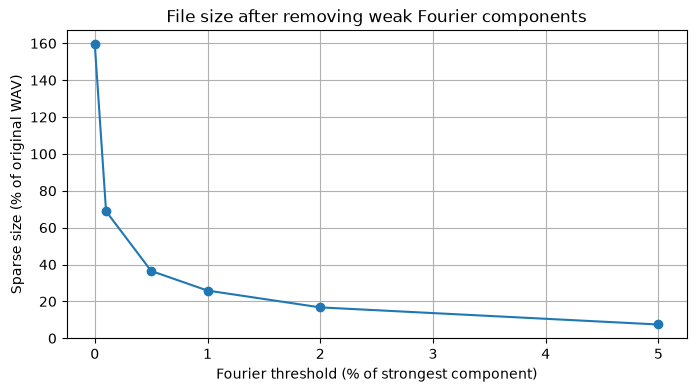

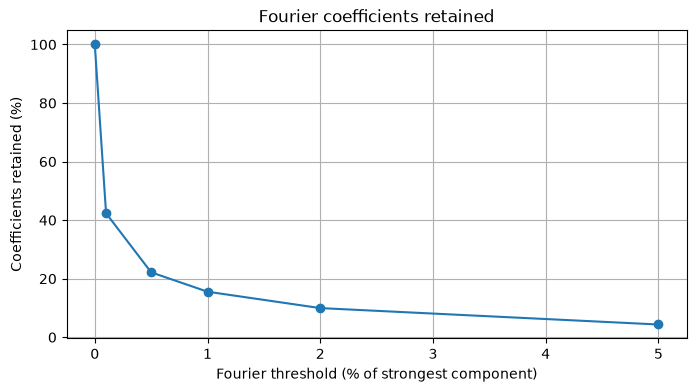

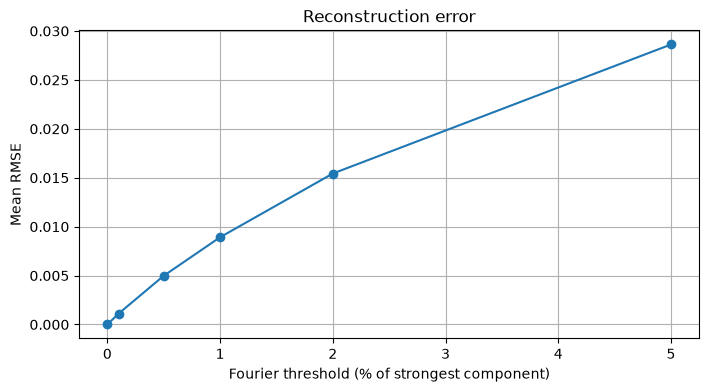

In [10]:
summary = []

for threshold in FOURIER_THRESHOLDS:
    r = fourier_results[threshold]

    kept_percent = (
        100 * r["kept_coefficients"] / r["total_coefficients"]
    )

    size_percent = (
        100 * r["sparse_bytes"] / r["original_bytes"]
    )

    reduction_percent = 100 - size_percent
    mean_rmse = float(np.mean(r["rmse"]))

    summary.append(
        (
            threshold,
            kept_percent,
            r["original_bytes"],
            r["sparse_bytes"],
            reduction_percent,
            mean_rmse,
        )
    )


# Print results
print(
    f"{'Threshold':>10} {'Kept %':>10} {'Original MiB':>14} "
    f"{'Sparse MiB':>12} {'Reduction %':>12} {'Mean RMSE':>12}"
)
print("-" * 76)

for threshold, kept, original, sparse, reduction, mean_rmse in summary:
    print(
        f"{threshold:10.3%} "
        f"{kept:10.2f} "
        f"{original / 2**20:14.2f} "
        f"{sparse / 2**20:12.2f} "
        f"{reduction:12.2f} "
        f"{mean_rmse:12.6f}"
    )


# Prepare plotting data
threshold_percent = [row[0] * 100 for row in summary]
kept_percent = [row[1] for row in summary]
size_percent = [100 - row[4] for row in summary]
mean_rmse = [row[5] for row in summary]


# Plot 1: file size
plt.figure(figsize=(8, 4))
plt.plot(threshold_percent, size_percent, marker="o")
plt.xlabel("Fourier threshold (% of strongest component)")
plt.ylabel("Sparse size (% of original WAV)")
plt.title("File size after removing weak Fourier components")
plt.grid()
plt.show()


# Plot 2: coefficients retained
plt.figure(figsize=(8, 4))
plt.plot(threshold_percent, kept_percent, marker="o")
plt.xlabel("Fourier threshold (% of strongest component)")
plt.ylabel("Coefficients retained (%)")
plt.title("Fourier coefficients retained")
plt.grid()
plt.show()


# Plot 3: reconstruction error
plt.figure(figsize=(8, 4))
plt.plot(threshold_percent, mean_rmse, marker="o")
plt.xlabel("Fourier threshold (% of strongest component)")
plt.ylabel("Mean RMSE")
plt.title("Reconstruction error")
plt.grid()
plt.show()

In [11]:
from IPython.display import Audio, display

# Choose which files to listen to
FILE_INDICES = [0, 1, 2]

# Choose Fourier threshold
# 0.001 = 0.1%
# 0.005 = 0.5%
# 0.01  = 1%
# 0.02  = 2%
# 0.05  = 5%
LISTEN_THRESHOLD = 0.1

for file_index in FILE_INDICES:
    wav_path = wav_files[file_index]

    signal, sample_rate = sf.read(
        wav_path,
        dtype="float32",
        always_2d=False
    )

    # Apply Fourier pruning
    indices, values, spectrum_shape, keep_mask = prune_fourier_components(
        signal,
        LISTEN_THRESHOLD
    )

    # Reconstruct the sound
    reconstructed = reconstruct_from_sparse_fourier(
        indices,
        values,
        spectrum_shape,
        signal.shape[0]
    )

    # Calculate some information
    kept_percent = 100 * keep_mask.sum() / keep_mask.size
    error = rmse(signal, reconstructed)

    print("=" * 70)
    print(f"File: {wav_path.name}")
    print(f"Threshold: {LISTEN_THRESHOLD * 100:.1f}%")
    print(f"Coefficients kept: {kept_percent:.2f}%")
    print(f"RMSE: {error:.6f}")

    print("\nORIGINAL:")
    display(
        Audio(
            np.clip(signal, -1, 1),
            rate=sample_rate,
            normalize=False
        )
    )

    print("AFTER FOURIER PRUNING:")
    display(
        Audio(
            np.clip(reconstructed, -1, 1),
            rate=sample_rate,
            normalize=False
        )
    )

File: 101415-3-0-2.wav
Threshold: 10.0%
Coefficients kept: 0.85%
RMSE: 0.034901

ORIGINAL:


AFTER FOURIER PRUNING:


File: 101415-3-0-3.wav
Threshold: 10.0%
Coefficients kept: 0.83%
RMSE: 0.037163

ORIGINAL:


AFTER FOURIER PRUNING:


File: 101415-3-0-8.wav
Threshold: 10.0%
Coefficients kept: 0.95%
RMSE: 0.031631

ORIGINAL:


AFTER FOURIER PRUNING:


In [12]:
# Difference between original and reconstructed signal
difference = signal - reconstructed

print("REMOVED / LOST INFORMATION:")
display(
    Audio(
        np.clip(difference, -1, 1),
        rate=sample_rate,
        normalize=False
    )
)

REMOVED / LOST INFORMATION:


File: 101415-3-0-2.wav
Threshold: 1.0%
RMSE: 0.004411
Kept coefficients: 5.65%


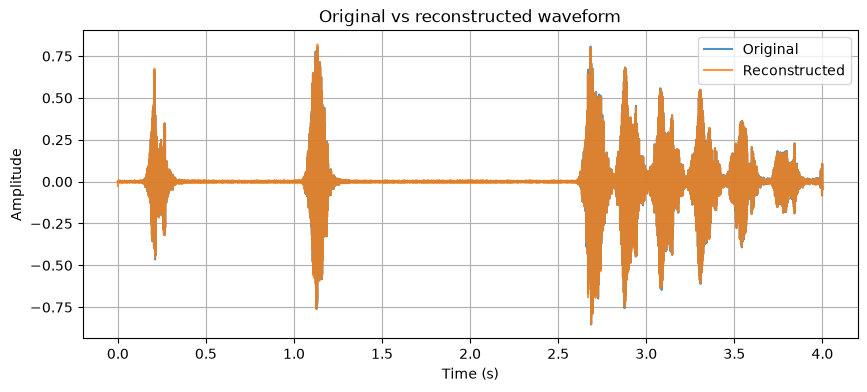

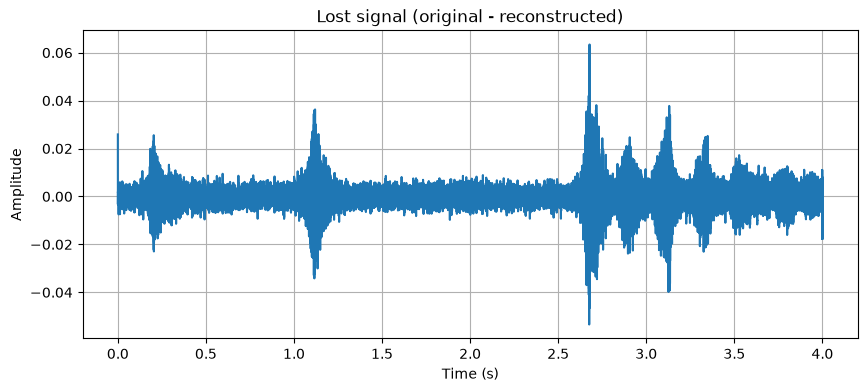

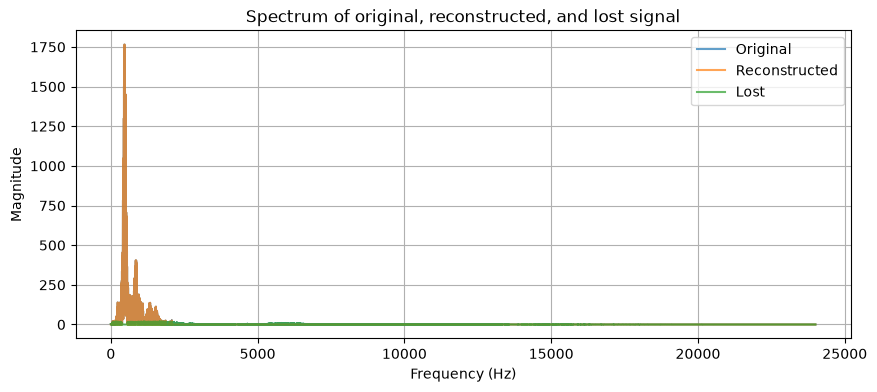

ORIGINAL AUDIO:


RECONSTRUCTED AUDIO:


LOST / REMOVED AUDIO:


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display

# Choose one file and one threshold
FILE_INDEX = 0
VIS_THRESHOLD = 0.01   # 1%

wav_path = wav_files[FILE_INDEX]

signal, sample_rate = sf.read(
    wav_path,
    dtype="float32",
    always_2d=False
)

indices, values, spectrum_shape, keep_mask = prune_fourier_components(
    signal,
    VIS_THRESHOLD
)

reconstructed = reconstruct_from_sparse_fourier(
    indices,
    values,
    spectrum_shape,
    signal.shape[0]
)

# If stereo, convert to mono for plotting
if signal.ndim > 1:
    signal_plot = signal.mean(axis=1)
    reconstructed_plot = reconstructed.mean(axis=1)
else:
    signal_plot = signal
    reconstructed_plot = reconstructed

lost_signal = signal_plot - reconstructed_plot

time = np.arange(len(signal_plot)) / sample_rate

print(f"File: {wav_path.name}")
print(f"Threshold: {VIS_THRESHOLD*100:.1f}%")
print(f"RMSE: {rmse(signal_plot, reconstructed_plot):.6f}")
print(f"Kept coefficients: {100 * keep_mask.sum() / keep_mask.size:.2f}%")

# 1. Original and reconstructed waveform
plt.figure(figsize=(10, 4))
plt.plot(time, signal_plot, label="Original", alpha=0.8)
plt.plot(time, reconstructed_plot, label="Reconstructed", alpha=0.8)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Original vs reconstructed waveform")
plt.legend()
plt.grid()
plt.show()

# 2. Lost signal (difference)
plt.figure(figsize=(10, 4))
plt.plot(time, lost_signal)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Lost signal (original - reconstructed)")
plt.grid()
plt.show()

# 3. Frequency spectrum
orig_fft = np.abs(np.fft.rfft(signal_plot))
recon_fft = np.abs(np.fft.rfft(reconstructed_plot))
lost_fft = np.abs(np.fft.rfft(lost_signal))
freqs = np.fft.rfftfreq(len(signal_plot), d=1/sample_rate)

plt.figure(figsize=(10, 4))
plt.plot(freqs, orig_fft, label="Original", alpha=0.7)
plt.plot(freqs, recon_fft, label="Reconstructed", alpha=0.7)
plt.plot(freqs, lost_fft, label="Lost", alpha=0.7)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Spectrum of original, reconstructed, and lost signal")
plt.legend()
plt.grid()
plt.show()

print("ORIGINAL AUDIO:")
display(Audio(signal_plot, rate=sample_rate, normalize=False))

print("RECONSTRUCTED AUDIO:")
display(Audio(reconstructed_plot, rate=sample_rate, normalize=False))

print("LOST / REMOVED AUDIO:")
display(Audio(lost_signal, rate=sample_rate, normalize=False))

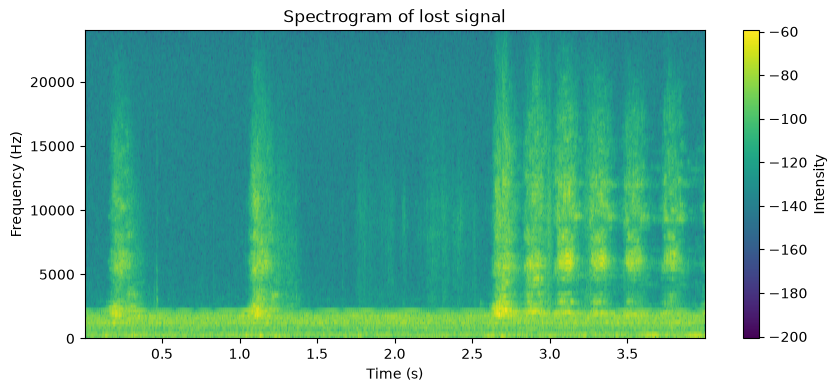

In [14]:
plt.figure(figsize=(10, 4))
plt.specgram(lost_signal, Fs=sample_rate)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram of lost signal")
plt.colorbar(label="Intensity")
plt.show()

### 5.) Who did what?

Nikolai started with this assignment. Katharina looked over the first part before finishing on the collaborated parts. We did each our experiment. Katharina did the filtering experiment and Nikolai did the quantization.